# A pendulum as a running example for SymPy

This tutorial introduces symbolic computation through one deliberately simple physical model: an ideal pendulum. It is intended for researchers who know basic Python and elementary calculus but are new to SymPy. Allow approximately 45–60 minutes for the core material and another 10 minutes for the practice task.

Run the notebook in the repository's default Pixi environment; no notebook-local installation is required. The model assumes a point mass, a massless rigid rod, uniform gravity, and no friction or forcing. These assumptions make the symbolic structure visible, but they do not describe every physical pendulum.

## Objectives

After working through the notebook, you should be able to:

- construct symbolic expressions and state assumptions about their symbols;
- distinguish a symbolic expression, an undefined symbolic function, and a numerical Python callable;
- substitute exact or numerical values into an expression;
- differentiate and integrate expressions in a scientifically meaningful calculation;
- use limits and series to justify and assess an approximation;
- verify a symbolic result by substitution or by checking a residual.

## Setup

Import SymPy with the conventional alias `sp`. NumPy is used only near the end, after the symbolic model has been constructed.

In [1]:
import sympy as sp

sp.init_printing()

## Model and notation

Let $m$ be the pendulum mass, $l$ the rod length, $g$ the gravitational acceleration, and $\theta$ the angle measured from the downward vertical.

![Ideal pendulum geometry with horizontal coordinate $x$, vertical coordinate $y$, angle $\theta$, length $l$, and mass $m$](img/pendulum.png)

The horizontal and vertical coordinates of the mass are

$$
x=l\sin\theta,
\qquad
y=-l\cos\theta.
$$

The choices $m>0$, $l>0$, and $g>0$ are part of the model. Encoding them as symbol assumptions helps SymPy make mathematically valid simplifications. The angle $\theta$ is real but need not be positive.

In [2]:
m, l, g = sp.symbols("m l g", positive=True)
theta = sp.symbols(r"\theta", real=True)

m.is_positive, l.is_positive, theta.is_real

(True, True, True)

## Constructing expressions

A SymPy expression represents a mathematical object; it is not a Python function that must be called. Ordinary Python operators compose symbols and SymPy functions into larger expression trees.

Taking the potential energy to be zero at the lowest point gives

$$
V(\theta)=mgl(1-\cos\theta),
$$

where $V$ is potential energy.

In [3]:
x = l*sp.sin(theta)
y = -l*sp.cos(theta)
potential_energy = m*g*(y + l)

x, y, potential_energy

Expressions know which symbols they contain. Sorting is used only to make the displayed order deterministic.

In [4]:
sorted(potential_energy.free_symbols, key=str)

### Substitution and evaluation

Substitution creates a new expression; SymPy expressions are immutable. Keeping $g=981/100$ exact postpones floating-point approximation until `evalf` is called. The units are documented here but are not automatically checked by this expression.

In [5]:
parameter_values = {
    m: sp.Rational(1, 4),       # kg
    l: sp.Rational(4, 5),       # m
    g: sp.Rational(981, 100),   # m / s**2
    theta: sp.pi/6,             # rad
}

exact_energy = potential_energy.subs(parameter_values)
exact_energy, exact_energy.evalf(6)

## Expressions and functions are different

Three related objects are easy to confuse:

1. `potential_energy` is an expression containing the mathematical function $\cos$;
2. $\theta(t)$ is an unknown symbolic function of time $t$;
3. a callable created by `lambdify` is ordinary executable Python code for numerical evaluation.

For time derivatives, $\theta$ must be represented as a function of time rather than as an independent symbol.

In [6]:
t = sp.symbols("t", real=True)
theta_function = sp.Function(r"\theta")
theta_t = theta_function(t)

theta_function, theta_t, sp.diff(theta_t, t)

(\theta, \theta(t), Derivative(\theta(t), t))

## Differentiation

The conservative torque $\tau$ is the negative derivative of potential energy with respect to angle:

$$
\tau(\theta)=-\frac{dV}{d\theta}.
$$

This derivative is with respect to the independent symbol $\theta$, not time.

In [7]:
torque = -sp.diff(potential_energy, theta)
torque

After substituting $\theta(t)$ for $\theta$, differentiating the coordinates with respect to $t$ applies the chain rule. The resulting kinetic energy $K$ simplifies using the identity $\sin^2\theta+\cos^2\theta=1$.

In [8]:
x_t = x.subs(theta, theta_t)
y_t = y.subs(theta, theta_t)
speed_squared = sp.diff(x_t, t)**2 + sp.diff(y_t, t)**2
kinetic_energy = sp.trigsimp(m*speed_squared/2)

sp.Eq(sp.Symbol("K"), kinetic_energy)

## Integration

Integration reverses the energy-to-torque calculation. Let $\phi$ be a dummy angle used only inside the integral. The change in potential energy from $0$ to $\theta$ is

$$
V(\theta)-V(0)=-\int_0^{\theta}\tau(\phi)\,d\phi.
$$

A distinct integration variable avoids using $\theta$ simultaneously as the integration variable and the upper limit.

In [9]:
phi = sp.symbols(r"\phi", real=True)
torque_phi = torque.subs(theta, phi)
recovered_energy = -sp.integrate(torque_phi, (phi, 0, theta))

recovered_energy

Do not accept a plausible-looking symbolic result without checking it. Here the simplified difference is exactly zero.

In [10]:
sp.simplify(recovered_energy - potential_energy)

## Limits and approximations

For small angles measured in radians, $\sin\theta$ is often replaced by $\theta$. A limit states precisely what “small” means locally. The ratio of the exact torque to the linearized torque tends to one as $\theta$ tends to zero:

$$
\lim_{\theta\to0}
\frac{-mgl\sin\theta}{-mgl\theta}=1.
$$

The limit justifies local asymptotic equivalence; it does not specify an acceptable angle for every application. That decision requires an error criterion.

In [11]:
linear_torque = -m*g*l*theta
torque_ratio = sp.cancel(torque/linear_torque)

torque_ratio, sp.limit(torque_ratio, theta, 0)

The corresponding quadratic approximation to the potential energy is

$$
V_{\mathrm{quad}}(\theta)=\frac{1}{2}mgl\theta^2.
$$

A second limit checks that the exact and approximate energies are also asymptotically equivalent.

In [12]:
quadratic_energy = m*g*l*theta**2/2
energy_ratio = potential_energy/quadratic_energy

sp.limit(energy_ratio, theta, 0)

### Series reveal the neglected terms

A limit confirms the leading-order behavior, whereas a series exposes the next corrections. The notation $O(\theta^6)$ collects terms of order $\theta^6$ and higher as $\theta\to0$.

In [13]:
energy_series = sp.series(potential_energy, theta, 0, 6)
energy_series

The order term records what the truncation has discarded. When a subsequent calculation specifically requires an ordinary polynomial-like expression, `removeO()` removes it. This is a deliberate loss of information: retain `energy_series` as well if the approximation order still matters.

In [14]:
truncated_energy = energy_series.removeO()
truncated_energy

## From symbolic expressions to numerical functions

`lambdify` translates a symbolic expression into a numerical Python callable. This is useful when symbolic derivation and numerical evaluation belong in the same workflow. It should not be confused with `sp.Function`, which represents an unknown mathematical function.

The following calculation measures the relative error made by replacing $\sin\theta$ with $\theta$ for several positive angles.

In [15]:
import numpy as np

relative_torque_error = (theta - sp.sin(theta))/sp.sin(theta)
error_function = sp.lambdify(theta, relative_torque_error, modules="numpy")

angles_degrees = np.array([5.0, 15.0, 30.0, 60.0])
errors = error_function(np.deg2rad(angles_degrees))

for angle_degrees, error in zip(angles_degrees, errors, strict=True):
    print(f"{angle_degrees:4.0f} degrees: {error:7.2%} relative torque error")

   5 degrees:   0.13% relative torque error
  15 degrees:   1.15% relative torque error
  30 degrees:   4.72% relative torque error
  60 degrees:  20.92% relative torque error


## Optional capstone: the equation of motion

The moment of inertia of the point mass about the pivot is $I=ml^2$. Combining $I\ddot{\theta}=\tau$ with the exact torque gives

$$
\ddot{\theta}(t)=-\frac{g}{l}\sin\theta(t).
$$

Here $\ddot{\theta}$ is the second derivative with respect to time. The mass cancels, so this ideal model predicts a period independent of mass.

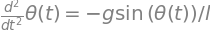

In [16]:
theta_ddot = sp.diff(theta_t, t, 2)
moment_of_inertia = m*l**2
angular_equation = sp.Eq(
    moment_of_inertia*theta_ddot,
    torque.subs(theta, theta_t),
)
exact_acceleration = sp.solve(angular_equation, theta_ddot)[0]

sp.Eq(theta_ddot, exact_acceleration)

Replacing $\sin\theta(t)$ by $\theta(t)$ produces a linear differential equation that SymPy can solve symbolically. Let $\theta_0$ be the release angle, with $\theta(0)=\theta_0$ and $\dot{\theta}(0)=0$.

In [17]:
theta_0 = sp.symbols(r"\theta_0", real=True)
linear_equation = sp.Eq(theta_ddot + (g/l)*theta_t, 0)
linear_solution = sp.dsolve(
    linear_equation,
    ics={
        theta_t.subs(t, 0): theta_0,
        sp.diff(theta_t, t).subs(t, 0): 0,
    },
)

linear_solution

Solver success is not a mathematical check. Substitute the proposed solution into the original linear equation and simplify its residual. A residual of zero verifies the differential equation symbolically; the initial conditions were supplied directly to `dsolve`.

In [18]:
solution_expression = linear_solution.rhs
ode_residual = sp.diff(solution_expression, t, 2) + (g/l)*solution_expression
initial_value_residual = solution_expression.subs(t, 0) - theta_0
initial_velocity_residual = sp.diff(solution_expression, t).subs(t, 0)

tuple(
    sp.simplify(residual)
    for residual in (
        ode_residual,
        initial_value_residual,
        initial_velocity_residual,
    )
)

## Practice: transfer the method

**Timebox:** 8–10 minutes.

A torsional spring has torque $\tau_s(\theta)=-\kappa\theta$, where $\kappa>0$ is its torsional stiffness.

1. Recover its potential energy relative to $\theta=0$ by integration.
2. Determine the value of $\kappa$ for which this potential energy equals the pendulum's quadratic small-angle energy.
3. Explain what this match does and does not imply about a real pendulum.

**Success criteria:** your potential differentiates back to $-\tau_s$, your value of $\kappa$ is dimensionally plausible, and your interpretation distinguishes a local approximation from a global identity.

**Hint:** use the dummy angle $\phi$ in the definite integral, then solve an equation for $\kappa$.

### Reference solution

In [19]:
kappa = sp.symbols(r"\kappa", positive=True)
spring_torque = -kappa*theta
spring_energy = -sp.integrate(
    spring_torque.subs(theta, phi),
    (phi, 0, theta),
)
matching_stiffness = sp.solve(
    sp.Eq(spring_energy, quadratic_energy),
    kappa,
)[0]
verification = sp.simplify(-sp.diff(spring_energy, theta) - spring_torque)

spring_energy, matching_stiffness, verification

The matching stiffness is $\kappa=mgl$. This makes the torsional-spring energy equal to the leading quadratic term of the pendulum energy near $\theta=0$. It does not make $\kappa\theta$ equal to $mgl\sin\theta$ at finite angles, and it does not restore effects omitted from the ideal pendulum model.

## Conclusions and next steps

The same pendulum model has connected SymPy's main object types and operations: symbols form expressions; an undefined function introduces time dependence; differentiation relates energy and torque; integration reverses that relationship; limits and series qualify an approximation; and `lambdify` turns a derived expression into numerical code.

The approximation is useful because its range of validity can be investigated, not because SymPy labels it correct. Symbol assumptions, model assumptions, and numerical error remain separate concerns.

For a more advanced derivation using Euler–Lagrange equations, continue with [the pendulums notebook](pendulums.ipynb). For nonlinear periods, ODE event detection, elliptic integrals, and quadrature, see [the nonlinear pendulum period notebook](../pendulum_period.ipynb).